# SHP2 Inhibitor SAR Analysis and Machine Learning Validation

**Author:** Yijie Zhu  
**Project:** Retrospective cheminformatics analysis of 35 published SHP2 allosteric inhibitors

## Research Question

How do structural modifications influence SHP2 inhibitory activity, and how reliably can machine-learning models predict experimentally measured inhibition within a small compound series?

## Project Overview

This project analyzes 35 published SHP2 allosteric inhibitors using Python, RDKit, and scikit-learn.

All 35 molecular structures were curated and verified, including stereochemical information. The computational workflow includes:

- Structure–activity relationship (SAR) analysis and visualization
- Calculation of physicochemical descriptors and chirality-aware Morgan fingerprints
- Molecular similarity analysis using Tanimoto coefficients
- Comparison of training-mean, nearest-neighbor, and random-forest regression models
- Evaluation using structural-family holdout and repeated connectivity-grouped cross-validation

**Prediction endpoint:** Percentage inhibition of SHP2 at 10 μM, rather than IC50.

## Key Findings

In leave-one-structural-family-out validation, the random forest achieved a mean absolute error (MAE) of **25.59 percentage points**, compared with **27.09** for the training-mean baseline.

In repeated connectivity-grouped cross-validation, the nearest-neighbor model achieved an MAE of **16.91 percentage points**, compared with **18.89** for the random forest.

A companion notebook, `SHP2_Step_8_Nested_Validation.ipynb`, investigates the effects of nested hyperparameter tuning.

## Interpretation

The results demonstrate the challenges of applying machine learning to small medicinal chemistry datasets, particularly when predicting compounds from previously unseen structural families. The analysis is retrospective and does not establish prospective predictive performance.

In [2]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()

if not (ROOT / "data" / "published_measurements.json").exists():
    ROOT = ROOT.parent

assert (ROOT / "data" / "published_measurements.json").exists(), (
    f"Cannot find project data from {Path.cwd()}"
)
OUT = ROOT / "results" / "reproduction_check"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
raw = json.loads((ROOT / 'data/published_measurements.json').read_text())
df = pd.DataFrame(raw['records'])
assert len(df) == 35 and df.compound_id.nunique() == 35
assert df.ic50_uM.notna().sum() == 24
assert df.inhibition_10uM_pct.between(0, 100).all()
assert (df.loc[df.ic50_uM.notna(), 'ic50_uM'] > 0).all()
df['pIC50'] = np.nan
known = df.ic50_uM.notna()
df.loc[known, 'pIC50'] = 6 - np.log10(df.loc[known, 'ic50_uM'])
df.to_csv(OUT / 'curated_measurements.csv', index=False)
print(f'{len(df)} compounds; {known.sum()} numerical IC50 values; {len(df)-known.sum()} missing IC50 values.')
print(df[['compound_id','inhibition_10uM_pct','ic50_uM','pIC50']].to_string(index=False))

35 compounds; 24 numerical IC50 values; 11 missing IC50 values.
compound_id  inhibition_10uM_pct  ic50_uM    pIC50
    SDUY038                   92      NaN      NaN
          1                   31      NaN      NaN
          2                   10      NaN      NaN
          3                   22      NaN      NaN
          4                   35      NaN      NaN
          5                   15      NaN      NaN
          6                   50      NaN      NaN
          7                   23      NaN      NaN
          8                   24      NaN      NaN
          9                   73     9.30 5.031517
         10                   87     2.50 5.602060
         11                   92     1.30 5.886057
         12                   38      NaN      NaN
         13                   96     0.95 6.022276
         14                   31      NaN      NaN
         15                   70     4.10 5.387216
         16                   88     2.90 5.537602
         17       

## 1. Inspect the complete assay endpoint
A value of 80 means 80% inhibition at 10 micromolar in this assay. Error bars are **published SEMs**, not raw replicate distributions. Do not duplicate rows to mimic the three experiments or triplicate wells.

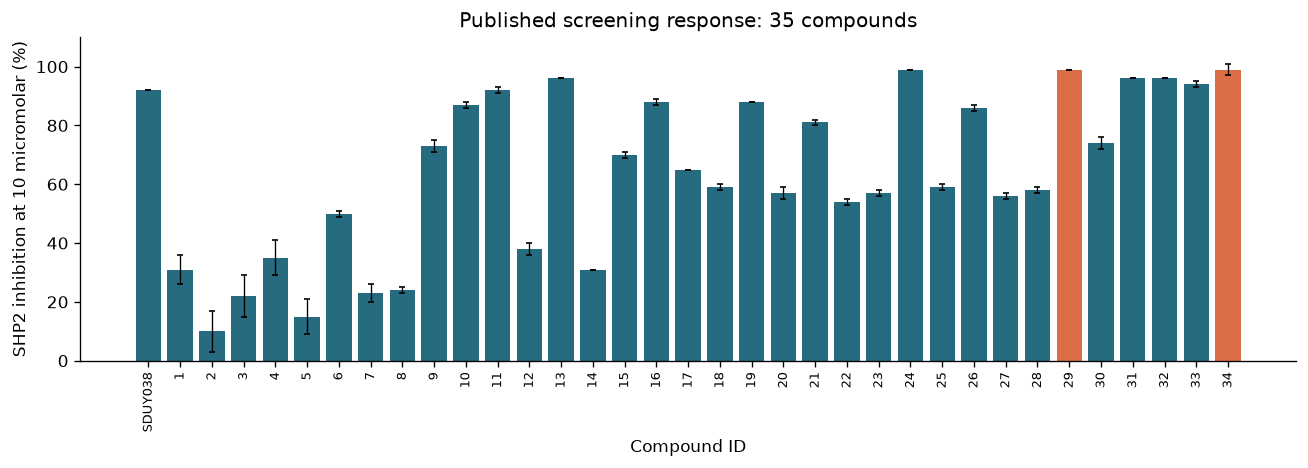

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
colors = ['#DB6D45' if c in ['29','34'] else '#276B80' for c in df.compound_id]
ax.bar(df.compound_id, df.inhibition_10uM_pct, yerr=df.inhibition_sem_pct,
       color=colors, capsize=2, error_kw={'elinewidth': 0.8})
ax.set(ylabel='SHP2 inhibition at 10 micromolar (%)', xlabel='Compound ID', ylim=(0,110),
       title='Published screening response: 35 compounds')
ax.tick_params(axis='x', rotation=90, labelsize=8)
fig.tight_layout()
fig.savefig(OUT / '01_screening_response.png', dpi=220)
plt.show()

## 2. Reconstruct a medicinal-chemistry SAR matrix
Each row keeps one aryl group and changes the terminal amine. Each column keeps the terminal amine and changes the aryl group. The cells show measured IC50 in micromolar; color shows pIC50. These are published findings being reanalyzed, not newly discovered compounds.

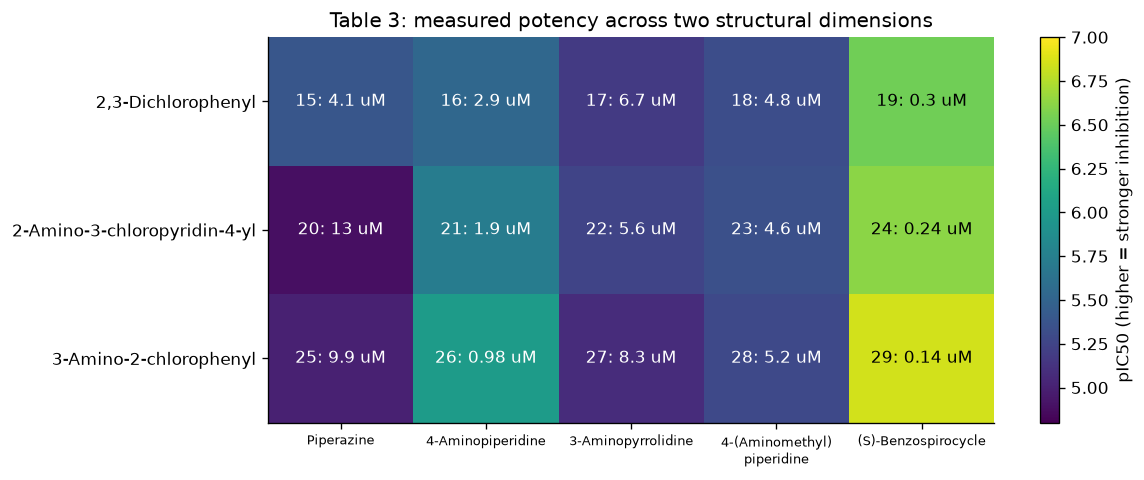

In [4]:
ids = [['15','16','17','18','19'], ['20','21','22','23','24'], ['25','26','27','28','29']]
lookup = df.set_index('compound_id')
ic = np.array([[lookup.loc[c,'ic50_uM'] for c in row] for row in ids], dtype=float)
potency = 6 - np.log10(ic)
fig, ax = plt.subplots(figsize=(10, 4.1))
im = ax.imshow(potency, cmap='viridis', vmin=4.8, vmax=7.0, aspect='auto')
ax.set_yticks(range(3), ['2,3-Dichlorophenyl', '2-Amino-3-chloropyridin-4-yl', '3-Amino-2-chlorophenyl'])
ax.set_xticks(range(5), ['Piperazine', '4-Aminopiperidine', '3-Aminopyrrolidine', '4-(Aminomethyl)\npiperidine', '(S)-Benzospirocycle'])
ax.tick_params(axis='x', labelsize=8)
for i in range(3):
    for j in range(5):
        ax.text(j, i, f'{ids[i][j]}: {ic[i,j]:g} uM', ha='center', va='center',
                color='black' if potency[i,j]>6.3 else 'white', fontsize=10)
ax.set_title('Table 3: measured potency across two structural dimensions')
fig.colorbar(im, ax=ax, label='pIC50 (higher = stronger inhibition)')
fig.tight_layout()
fig.savefig(OUT / '02_SAR_matrix.png', dpi=220)
plt.show()

## 3. Explain the stereochemical activity difference
29 (SDUY104) and 34 are reported as S and R enantiomers. Both have a mean screen value of 99%, yet their enzymatic IC50 values differ. Do not convert AlphaScreen values (1.5 and 9.8 micromolar) into this endpoint.

Compound 29 is 14.29-fold more potent by the reported mean enzymatic IC50.
pIC50 difference = 1.155. This is descriptive; no raw-data significance test is performed.


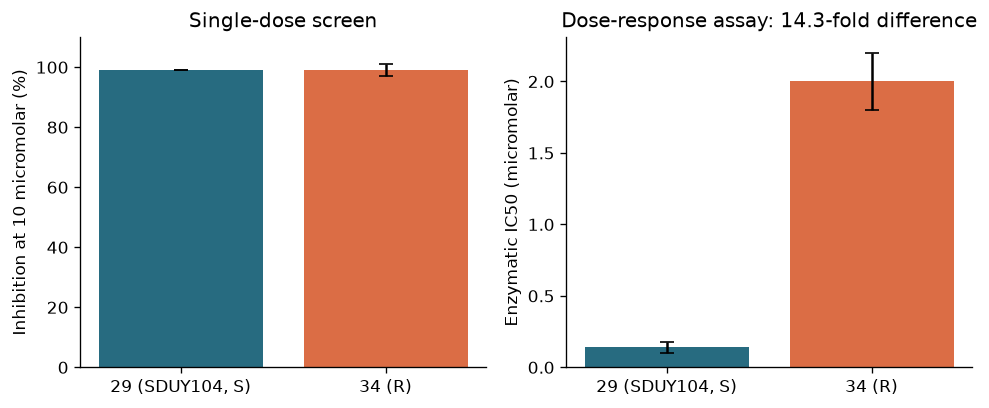

In [5]:
pair = lookup.loc[['29','34']]
fold = pair.loc['34','ic50_uM'] / pair.loc['29','ic50_uM']
delta = pair.loc['29','pIC50'] - pair.loc['34','pIC50']
print(f'Compound 29 is {fold:.2f}-fold more potent by the reported mean enzymatic IC50.')
print(f'pIC50 difference = {delta:.3f}. This is descriptive; no raw-data significance test is performed.')
fig, axes = plt.subplots(1,2,figsize=(8.3,3.5))
labels=['29 (SDUY104, S)', '34 (R)']
axes[0].bar(labels,pair.inhibition_10uM_pct,yerr=pair.inhibition_sem_pct,color=['#276B80','#DB6D45'],capsize=4)
axes[0].set(ylabel='Inhibition at 10 micromolar (%)',ylim=(0,110),title='Single-dose screen')
axes[1].bar(labels,pair.ic50_uM,yerr=pair.ic50_sem_uM,color=['#276B80','#DB6D45'],capsize=4)
axes[1].set(ylabel='Enzymatic IC50 (micromolar)',title=f'Dose-response assay: {fold:.1f}-fold difference')
fig.tight_layout()
fig.savefig(OUT / '03_stereochemistry_endpoint.png',dpi=220)
plt.show()

## 4. Verify the curated molecular structures

All 35 molecular structures have been curated and stored in `data/structures.json`, with SMILES representations, source information, stereochemistry notes, and verification flags.

The following analysis uses these verified structures. The original structure-import procedure is preserved in a Raw cell for documentation but is intentionally not executed, preventing accidental overwriting of the curated dataset.

Preserve stereochemistry and the exact salt/parent representation consistently. For a multi-fragment salt, manually document the counterion removal and record the parent SMILES here. This notebook refuses dot-separated inputs to prevent silent changes. Do not infer a structure from a molecular formula. If a stereocenter is unspecified in the source, record that fact instead of inventing a configuration.

For 29 and 34 confirm the opposite configurations at the homologous center. `@` and `@@` by themselves do not mean S and R independently of atom order. The RDKit output must be checked against the paper. The code deliberately stops on unverified entries. It does not silently train on a convenient subset.

Structure discrepancy: compounds 20–24. Table 3 depicts a dichloropyridinyl group, whereas the supplementary CSV, the compound names and molecular formulas in the Experimental Section (p. 1479), and the structures accompanying the spectra in Supporting Information pp. S36–S40 support a 2-amino-3-chloropyridin-4-yl group. The CSV structures were retained on this basis. The Table 3 depiction is treated as a suspected drawing error.

Successfully parsed 35 structures.
29 [(26, 'S')]
34 [(25, 'R')]


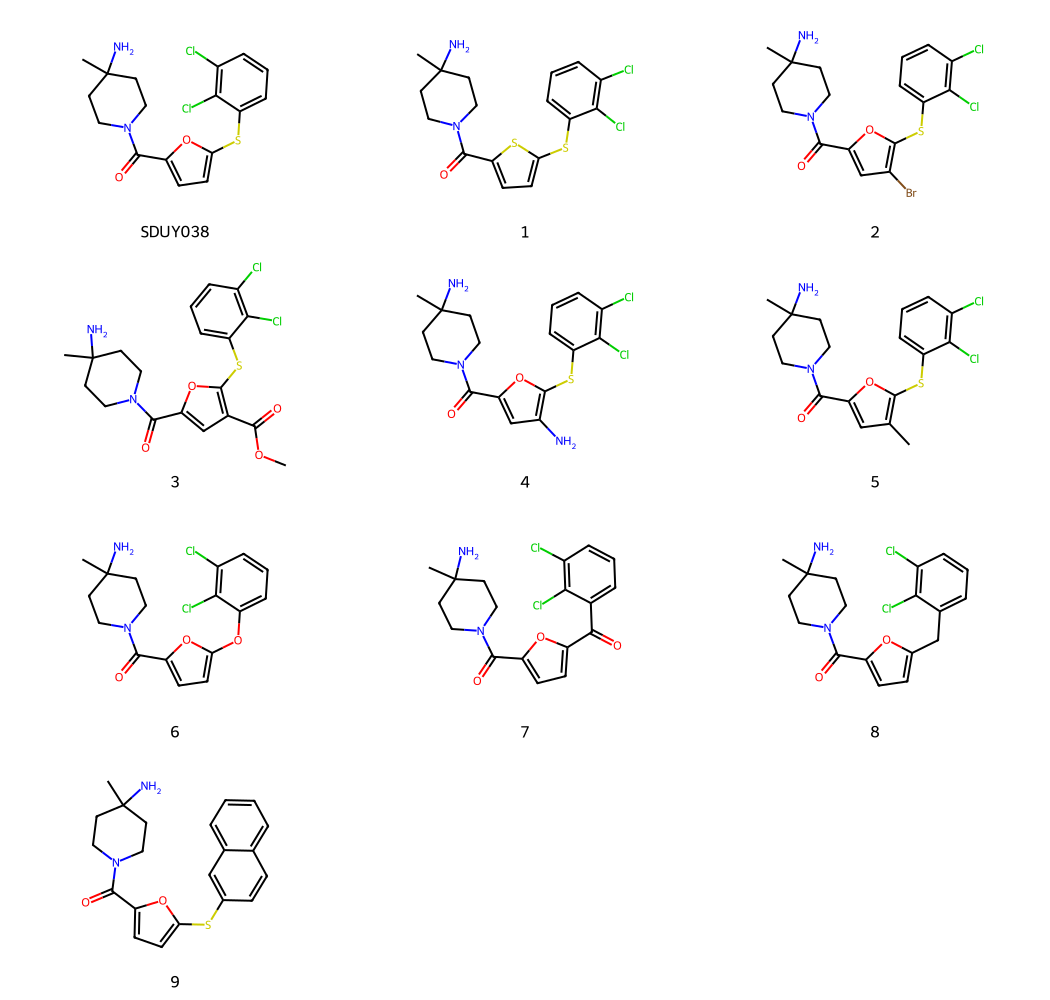

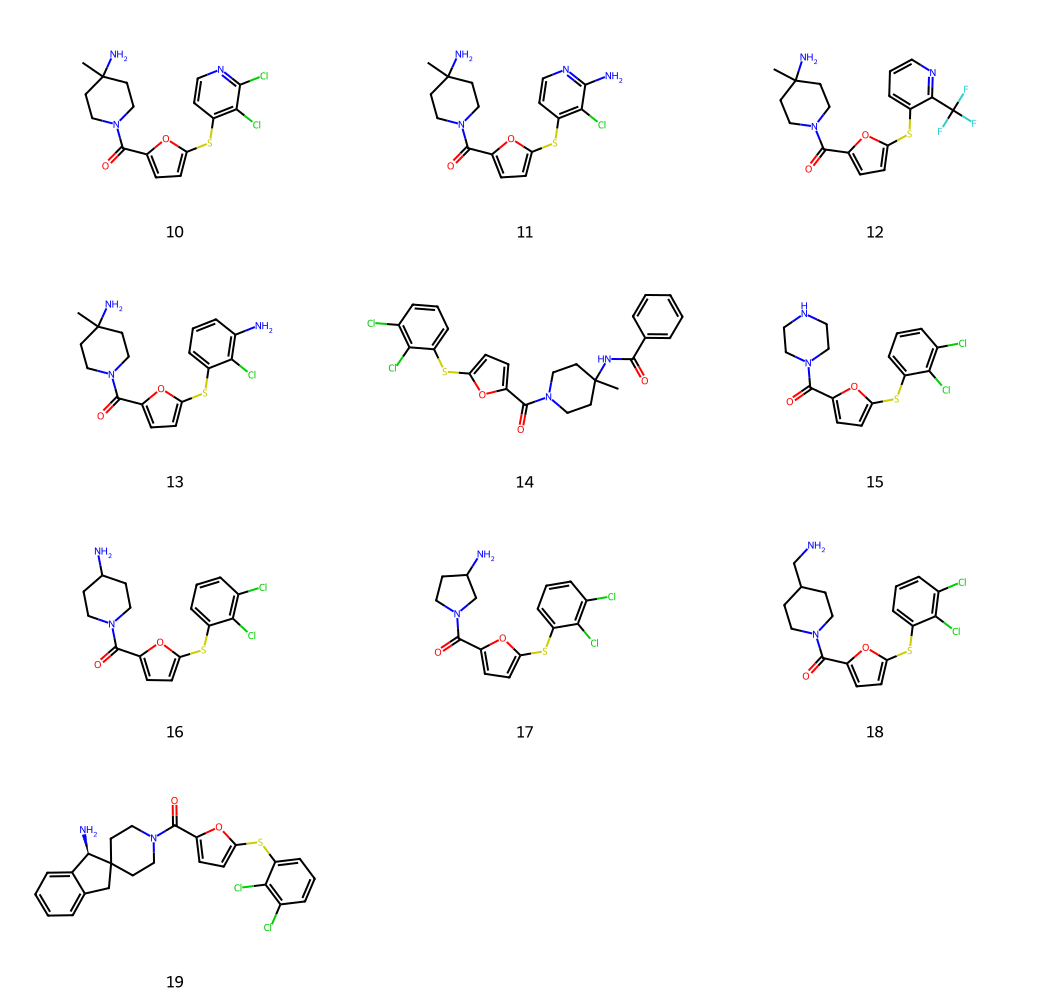

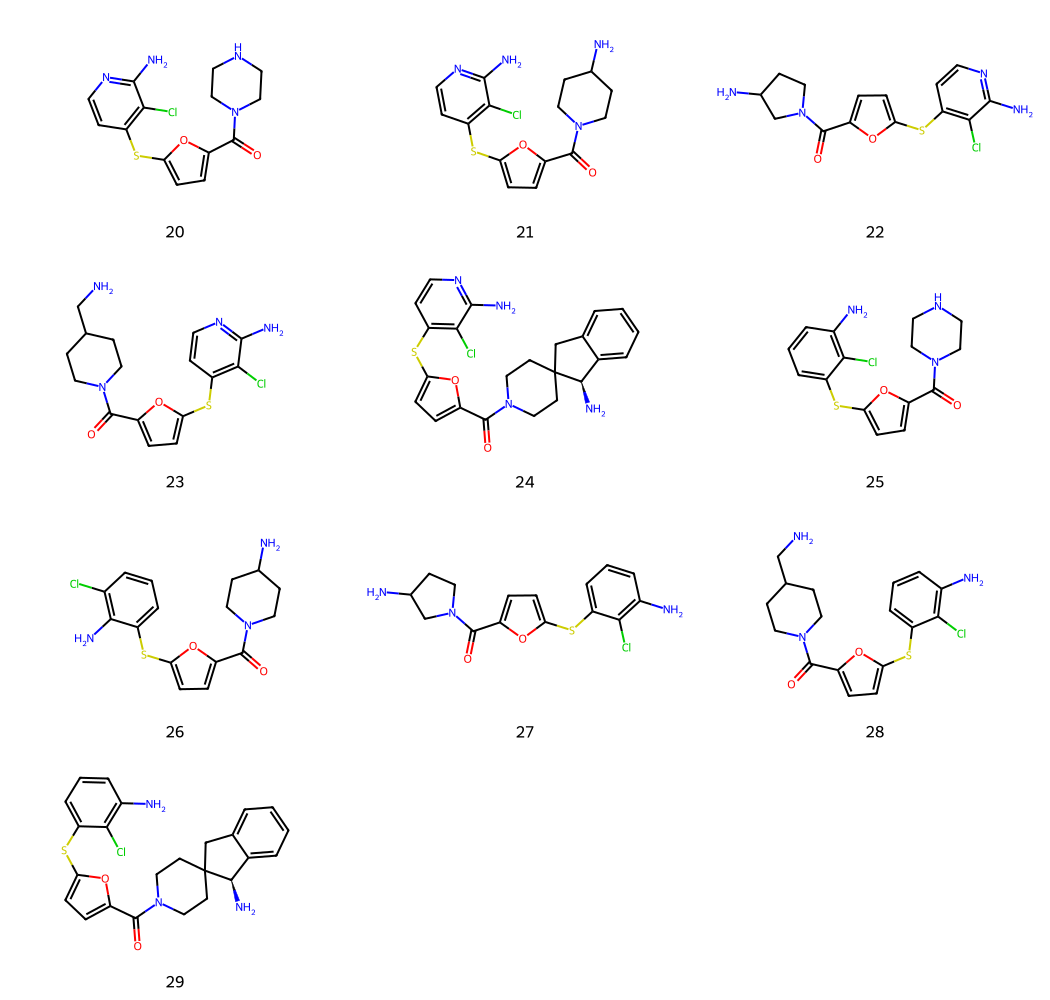

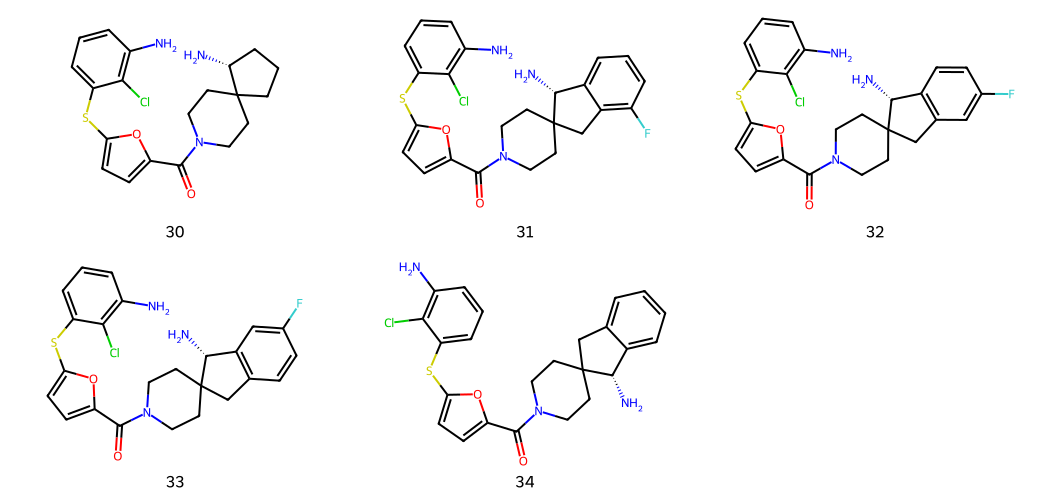

In [6]:
import csv
from pathlib import Path
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import display

csv_path = ROOT / "data" / "raw" / "jm6c00836_si_004.csv"

with csv_path.open(encoding="utf-8-sig", newline="") as f:
    rows = list(csv.DictReader(f))

molecules = {}

for row in rows:
    compound_id = row["Compound_ID"].strip()

    if not compound_id or compound_id in {"SHP099", "TNO155"}:
        continue

    if compound_id == "29(SDUY104)":
        compound_id = "29"

    mol = Chem.MolFromSmiles(row["SMILES"].strip())
    assert mol is not None, f"Invalid SMILES: {compound_id}"
    assert compound_id not in molecules, f"Duplicate ID: {compound_id}"
    molecules[compound_id] = mol

expected = {"SDUY038"} | {str(i) for i in range(1, 35)}
assert set(molecules) == expected, "Compound IDs do not match the project"

print(f"Successfully parsed {len(molecules)} structures.")

for compound_id in ["29", "34"]:
    print(compound_id, Chem.FindMolChiralCenters(
        molecules[compound_id], includeUnassigned=True
    ))

ids = ["SDUY038"] + [str(i) for i in range(1, 35)]

for start in range(0, len(ids), 10):
    batch = ids[start:start + 10]
    display(Draw.MolsToGridImage(
        [molecules[i] for i in batch],
        legends=batch,
        molsPerRow=3,
        subImgSize=(350, 250)
    ))

29 [(26, 'S')]
34 [(25, 'R')]


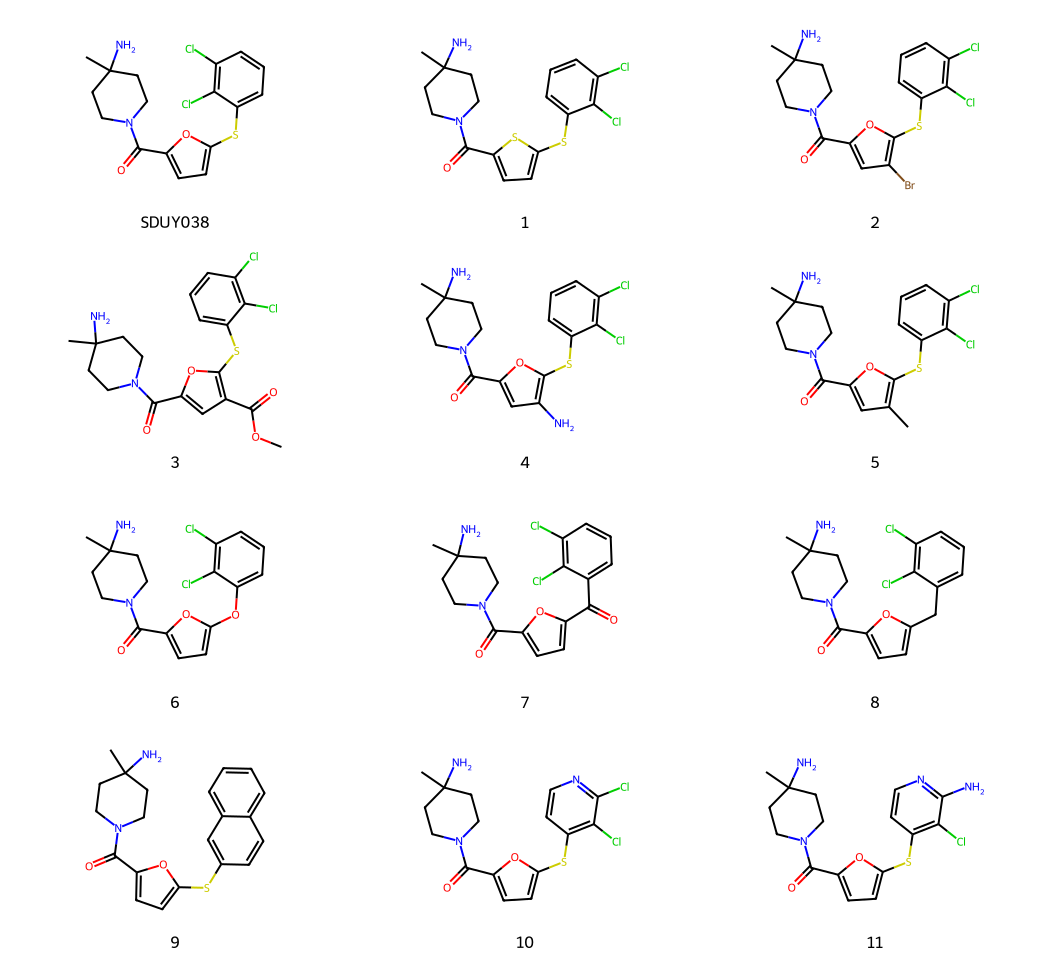

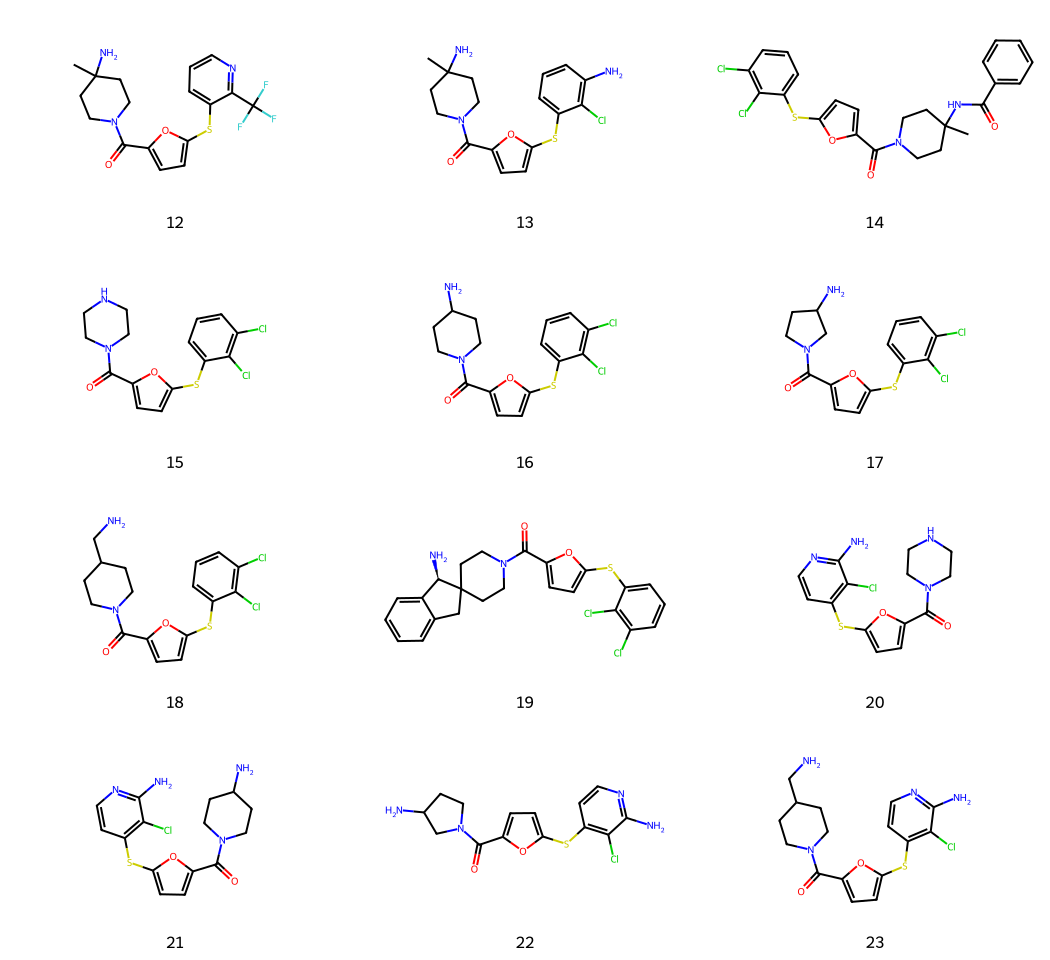

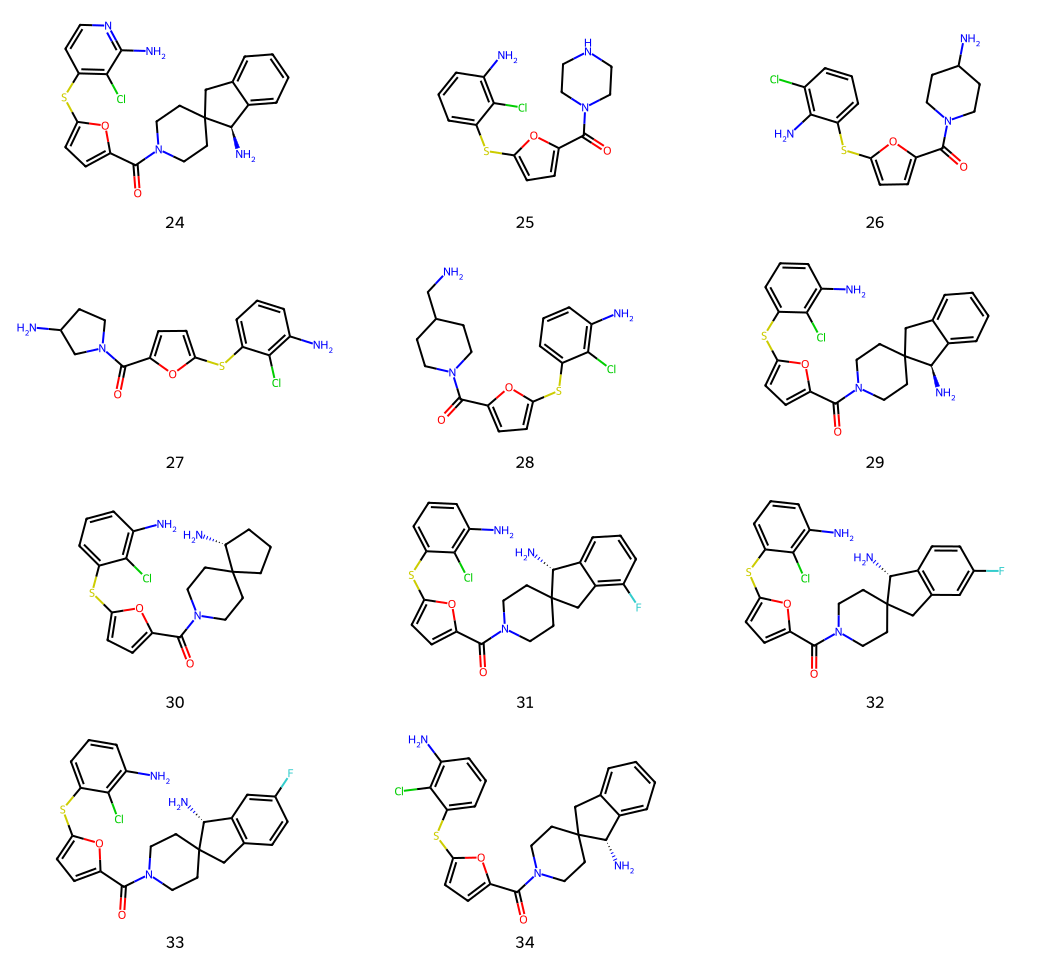

Structure validation and file saving completed.


In [7]:
from rdkit import Chem, DataStructs, rdBase
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors, rdFingerprintGenerator, Draw

structures = json.loads((ROOT / 'data/structures.json').read_text())
assert set(structures) == set(df.compound_id), 'Structure IDs must exactly match the 35 measurement IDs.'
bad = [c for c in df.compound_id if not structures[c]['smiles'].strip()
       or structures[c]['verified'] is not True or not structures[c]['source'].strip()
       or not structures[c]['stereo_note'].strip()]
if bad:
    raise ValueError('Fill and verify all structure fields before modeling. Incomplete IDs: ' + ', '.join(bad))
mols=[]
for cid in df.compound_id:
    smi=structures[cid]['smiles'].strip()
    if '.' in smi:
        raise ValueError(f'{cid}: document a consistent parent structure; do not silently remove fragments.')
    mol=Chem.MolFromSmiles(smi)
    if mol is None or mol.GetNumAtoms()==0:
        raise ValueError(f'{cid}: invalid SMILES')
    Chem.AssignStereochemistry(mol, cleanIt=True, force=True)
    mols.append(mol)
df['canonical_isomeric_smiles']=[Chem.MolToSmiles(m, isomericSmiles=True) for m in mols]
df['connectivity_key']=[Chem.MolToSmiles(m, isomericSmiles=False) for m in mols]
if df.canonical_isomeric_smiles.duplicated().any():
    raise ValueError('Duplicate isomeric structures found: review compound mapping before training.')
a,b = [int(df.index[df.compound_id.eq(c)][0]) for c in ['29','34']]
assert df.loc[a,'connectivity_key']==df.loc[b,'connectivity_key'], '29 and 34 should share connectivity.'
assert df.loc[a,'canonical_isomeric_smiles']!=df.loc[b,'canonical_isomeric_smiles'], '29 and 34 must retain stereochemistry.'
for i in [a,b]:
    print(df.loc[i,'compound_id'], Chem.FindMolChiralCenters(mols[i],includeUnassigned=True))
assert [x[1] for x in Chem.FindMolChiralCenters(mols[a],includeUnassigned=True)] == ['S'], 'Verify compound 29 configuration.'
assert [x[1] for x in Chem.FindMolChiralCenters(mols[b],includeUnassigned=True)] == ['R'], 'Verify compound 34 configuration.'
from IPython.display import display
for start in range(0, len(mols), 12):
    grid = Draw.MolsToGridImage(
        mols[start:start + 12],
        molsPerRow=3,
        subImgSize=(350, 240),
        legends=df.compound_id.iloc[start:start + 12].tolist(),
        useSVG=False
    )

    image_path = OUT / f"structures_{start + 1:02d}.png"

    if hasattr(grid, "save"):
        grid.save(str(image_path))
    else:
        image_path.write_bytes(grid.data)

    display(grid)

df.to_csv(
    OUT / "verified_structures_and_measurements.csv",
    index=False
)

print("Structure validation and file saving completed.")

## 5. Translate molecules into numerical features
The seven descriptors summarize size, calculated lipophilicity, polarity, hydrogen bonding, flexibility, and carbon saturation. They describe chemistry; they do not prove safety or bioavailability.

Morgan fingerprints encode local atom environments. Radius 2 covers neighborhoods within two bonds, and 2048 specifies the bit-vector length. `includeChirality=True` retains supported stereochemical information. Chirality-aware features can distinguish enantiomers but do not guarantee accurate stereoselectivity predictions. Descriptors are used for interpretation only; the fixed benchmark uses fingerprints alone.

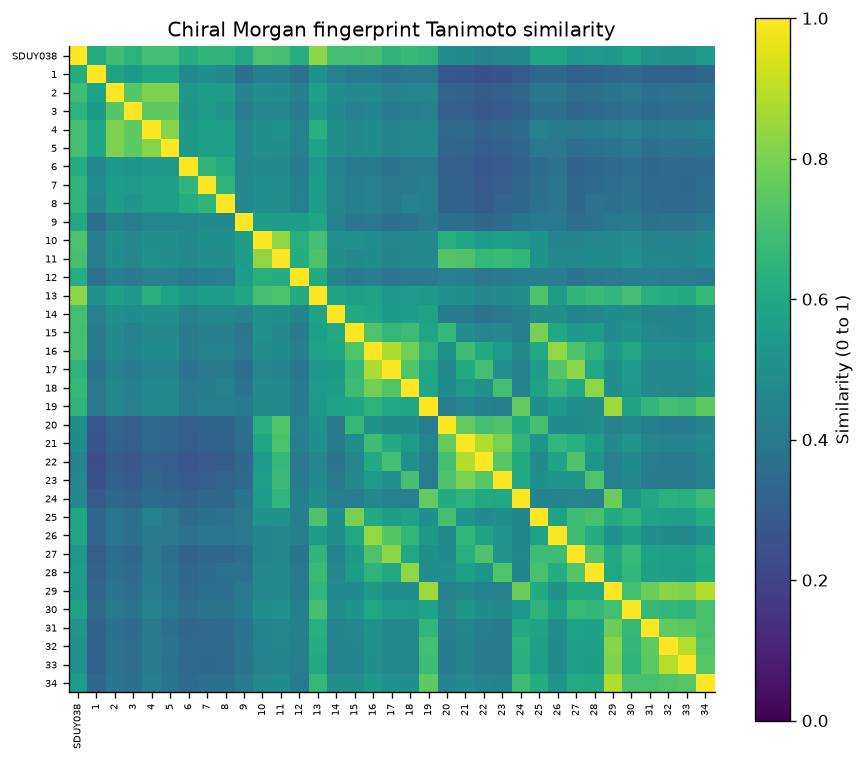

In [8]:
descriptors=pd.DataFrame({
    'compound_id':df.compound_id,
    'MW':[Descriptors.MolWt(m) for m in mols],
    'cLogP':[Crippen.MolLogP(m) for m in mols],
    'TPSA':[rdMolDescriptors.CalcTPSA(m) for m in mols],
    'HBD':[Lipinski.NumHDonors(m) for m in mols],
    'HBA':[Lipinski.NumHAcceptors(m) for m in mols],
    'rotatable_bonds':[Lipinski.NumRotatableBonds(m) for m in mols],
    'fraction_Csp3':[rdMolDescriptors.CalcFractionCSP3(m) for m in mols]
})
descriptors.to_csv(OUT/'descriptors.csv',index=False)
gen=rdFingerprintGenerator.GetMorganGenerator(radius=2,fpSize=2048,includeChirality=True)
fps=[gen.GetFingerprint(m) for m in mols]
X=np.vstack([gen.GetFingerprintAsNumPy(m) for m in mols])
y=df.inhibition_10uM_pct.to_numpy(dtype=float)
similarity=np.array([DataStructs.BulkTanimotoSimilarity(fp,fps) for fp in fps])
assert X.shape==(35,2048) and np.isfinite(X).all()
pd.DataFrame(similarity,index=df.compound_id,columns=df.compound_id).to_csv(OUT/'similarity_matrix.csv')
fig,ax=plt.subplots(figsize=(7.5,6.5))
im=ax.imshow(similarity,vmin=0,vmax=1,cmap='viridis')
ax.set_xticks(range(len(df)),df.compound_id,rotation=90,fontsize=6)
ax.set_yticks(range(len(df)),df.compound_id,fontsize=6)
ax.set_title('Chiral Morgan fingerprint Tanimoto similarity')
fig.colorbar(im,ax=ax,label='Similarity (0 to 1)')
fig.tight_layout()
fig.savefig(OUT/'04_similarity_matrix.png',dpi=220)
plt.show()

In [9]:
print("Descriptor table:", descriptors.shape)
print("Fingerprint array:", X.shape)
print("Activity target:", y.shape)
print("Similarity matrix:", similarity.shape)

display(descriptors.head())

compound_ids = df.compound_id.tolist()
i29 = compound_ids.index("29")
i34 = compound_ids.index("34")

print(
    "Fingerprint similarity between 29 and 34:",
    round(float(similarity[i29, i34]), 3)
)

Descriptor table: (35, 8)
Fingerprint array: (35, 2048)
Activity target: (35,)
Similarity matrix: (35, 35)


,compound_id,MW,cLogP,TPSA,HBD,HBA,rotatable_bonds,fraction_Csp3
0,SDUY038,385.316,4.6910,59.47,1,4,3,0.352941
1,1,401.384,5.1595,46.33,1,4,3,0.352941
2,2,464.212,5.4535,59.47,1,4,3,0.352941
3,3,443.352,4.4776,85.77,1,6,4,0.368421
4,4,400.331,4.2732,85.49,2,5,3,0.352941


Fingerprint similarity between 29 and 34: 0.885


Figure 4 interpretation

The matrix compares 35 compounds using Tanimoto similarity
calculated from chiral Morgan fingerprints. Similarity describes
the molecular representation, not biological activity.

Compounds 29 and 34 have a similarity of 0.885. Their shared
connectivity produces substantial overlap, while stereochemistry
changes some fingerprint features.

Both have 99% inhibition at 10 μM despite a 14.3-fold IC50
difference, illustrating information lost in the single-dose endpoint.

In [10]:
print("Descriptor table:", descriptors.shape)
print("Fingerprint array:", X.shape)
print("Activity target:", y.shape)
print("Similarity matrix:", similarity.shape)

Descriptor table: (35, 8)
Fingerprint array: (35, 2048)
Activity target: (35,)
Similarity matrix: (35, 35)


## 6. Freeze the benchmark before viewing its scores
Main outcome: MAE in **percentage points** on inhibition at 10 micromolar. Models: a training-mean baseline, nearest-neighbor by Tanimoto similarity, and one random forest (200 trees, minimum leaf size 2, max_features='sqrt', seed 42). Tied nearest neighbors are averaged. No tuning or feature selection is performed.

**Primary stress test:** Leave one of the five prespecified structural-modification families out. These are chemistry families, not rigorously separated scaffolds. Related analogues may still occur across families, so also inspect the maximum similarity to the training set. The small 3-compound linker fold is particularly unstable.

**Secondary interpolation test:** ten repeats of five-fold splitting of connectivity groups. All stereoisomers with the same connectivity stay together. These repeated estimates reuse molecules and are not ten independent datasets. An opposite enantiomer never appears in training for a held-out member of its pair.

Neither result is an independent external validation. Family IDs, compound IDs, SEM, IC50, pIC50, and publication labels never enter X.

In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr

def evaluate_splits(X,y,similarity,df,splits,scheme,repeat=0):
    rows=[]
    for fold,(train,test) in enumerate(splits):
        assert not set(train)&set(test)
        assert not set(df.iloc[train].connectivity_key)&set(df.iloc[test].connectivity_key)
        forest=RandomForestRegressor(n_estimators=200,min_samples_leaf=2,
                                     max_features='sqrt',random_state=42,n_jobs=1)
        forest.fit(X[train],y[train])
        forest_pred=forest.predict(X[test])
        sim=similarity[np.ix_(test,train)]
        best=sim.max(axis=1)
        nn=np.array([y[train][np.isclose(s,b)].mean() for s,b in zip(sim,best)])
        for k,idx in enumerate(test):
            rows.append(dict(compound_id=df.iloc[idx].compound_id,scheme=scheme,repeat=repeat,fold=fold,
                family=df.iloc[idx].family,observed=float(y[idx]),mean_baseline=float(y[train].mean()),
                nearest_neighbor=float(nn[k]),random_forest=float(forest_pred[k]),
                max_train_similarity=float(best[k]),n_train=len(train)))
    result=pd.DataFrame(rows)
    assert len(result)==len(y) and result.compound_id.nunique()==len(y)
    return result

def scores(frame):
    rows=[]
    for model in ['mean_baseline','nearest_neighbor','random_forest']:
        truth=frame.observed.to_numpy()
        pred=frame[model].to_numpy()
        rho=float(spearmanr(truth,pred).statistic) if len(set(pred))>1 and len(set(truth))>1 else np.nan
        rows.append(dict(model=model,n=len(frame),MAE_pp=mean_absolute_error(truth,pred),
                         RMSE_pp=np.sqrt(mean_squared_error(truth,pred)),
                         R2=r2_score(truth,pred) if len(frame)>1 else np.nan,Spearman_rho=rho))
    return pd.DataFrame(rows)

logo=LeaveOneGroupOut()
primary=evaluate_splits(X,y,similarity,df,list(logo.split(X,y,df.family)), 'leave_family_out')
primary_scores=scores(primary)
primary_scores.to_csv(OUT/'primary_pooled_metrics.csv',index=False)
per_family=pd.concat([scores(g).assign(family=name) for name,g in primary.groupby('family')],ignore_index=True)
per_family.to_csv(OUT/'primary_metrics_by_family.csv',index=False)
per_family.groupby('model').MAE_pp.mean().rename('macro_family_MAE_pp').to_csv(OUT/'primary_macro_family_MAE.csv')
print('PRIMARY: one out-of-fold prediction per compound')
print(primary_scores.to_string(index=False))
print('Per-family MAE:')
print(per_family[['family','model','n','MAE_pp']].to_string(index=False))

connectivity=df.connectivity_key.to_numpy()
unique=np.array(sorted(set(connectivity)))
secondary=[]
for repeat in range(10):
    splits=[]
    for tr,te in KFold(n_splits=5,shuffle=True,random_state=42+repeat).split(unique):
        splits.append((np.flatnonzero(np.isin(connectivity,unique[tr])),
                       np.flatnonzero(np.isin(connectivity,unique[te]))))
    secondary.append(evaluate_splits(X,y,similarity,df,splits,'grouped_random_5fold',repeat))
secondary=pd.concat(secondary,ignore_index=True)
secondary_scores=pd.concat([scores(g).assign(repeat=r) for r,g in secondary.groupby('repeat')],ignore_index=True)
secondary_scores.to_csv(OUT/'secondary_metrics_each_repeat.csv',index=False)
print('SECONDARY: mean and SD over repeated split estimates; not a confidence interval')
print(secondary_scores.groupby('model')[['MAE_pp','RMSE_pp','R2','Spearman_rho']].agg(['mean','std']))
predictions=pd.concat([primary,secondary],ignore_index=True)
predictions.to_csv(OUT/'all_out_of_fold_predictions.csv',index=False)

PRIMARY: one out-of-fold prediction per compound
           model  n    MAE_pp   RMSE_pp        R2  Spearman_rho
   mean_baseline 35 27.093744 31.640163 -0.323086     -0.831421
nearest_neighbor 35 30.800000 39.042102 -1.014546      0.226867
   random_forest 35 25.591438 28.678930 -0.087018     -0.129139
Per-family MAE:
                 family            model  n    MAE_pp
           central_ring    mean_baseline  5 48.766667
           central_ring nearest_neighbor  5 69.400000
           central_ring    random_forest  5 39.942497
                 linker    mean_baseline  3 35.072917
                 linker nearest_neighbor  3 59.666667
                 linker    random_forest  3 20.983984
nonspiro_terminal_amine    mean_baseline 12  9.775362
nonspiro_terminal_amine nearest_neighbor 12 25.333333
nonspiro_terminal_amine    random_forest 12 13.246377
  parent_and_aryl_amide    mean_baseline  7 26.290816
  parent_and_aryl_amide nearest_neighbor  7 29.571429
  parent_and_aryl_amide    rand

## 7. Inspect failures and write the result
The diagonal on the prediction plot is perfect agreement. Points far away identify errors to examine chemically. Compare the random forest with **both** baselines and report every family, including poor ones. A higher similarity does not guarantee accuracy: activity cliffs are an exception.

Write two paragraphs: (1) what the measured SAR shows, and (2) what the benchmark can and cannot predict. If the forest is no better than the mean or nearest-neighbor baseline, say so and keep the SAR analysis as the main finding. Do not adjust settings after seeing these scores and describe the revised score as untouched validation.

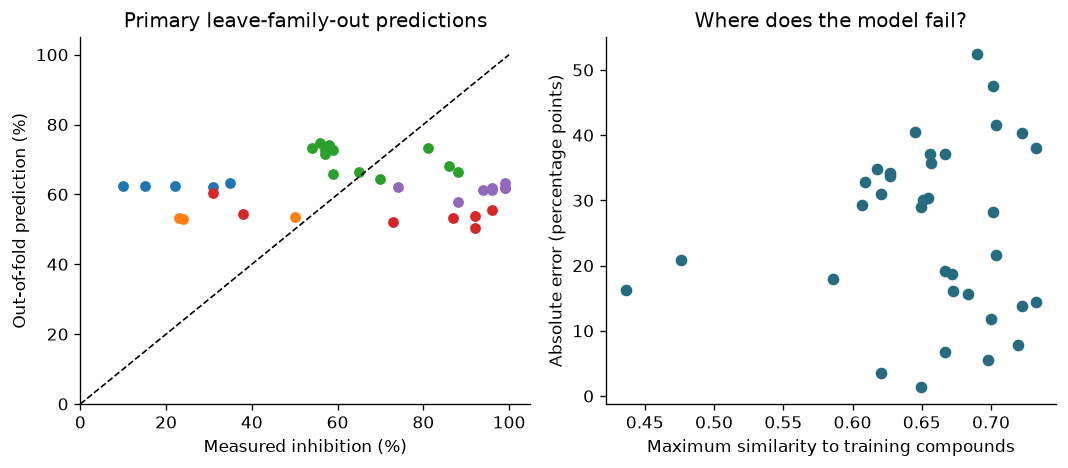

compound_id                family  observed  random_forest  absolute_error_pp  max_train_similarity
          2          central_ring      10.0      62.465643          52.465643              0.689655
          5          central_ring      15.0      62.465643          47.465643              0.701754
    SDUY038 parent_and_aryl_amide      92.0      50.420276          41.579724              0.703704
          3          central_ring      22.0      62.465643          40.465643              0.645161
         13 parent_and_aryl_amide      96.0      55.631089          40.368911              0.722222
         11 parent_and_aryl_amide      92.0      53.923403          38.076597              0.732143
         34            spirocycle      99.0      61.853810          37.146190              0.666667
         29            spirocycle      99.0      61.853810          37.146190              0.656250


206

In [11]:
fig,axes=plt.subplots(1,2,figsize=(9,4))
for family,part in primary.groupby('family'):
    axes[0].scatter(part.observed,part.random_forest,label=family,s=30)
axes[0].plot([0,100],[0,100],'k--',linewidth=1)
axes[0].set(xlabel='Measured inhibition (%)',ylabel='Out-of-fold prediction (%)',
            title='Primary leave-family-out predictions',xlim=(0,105),ylim=(0,105))
axes[1].scatter(primary.max_train_similarity,abs(primary.observed-primary.random_forest),color='#276B80')
axes[1].set(xlabel='Maximum similarity to training compounds',ylabel='Absolute error (percentage points)',
            title='Where does the model fail?')
fig.tight_layout()
fig.savefig(OUT/'05_benchmark_diagnostics.png',dpi=220)
plt.show()
errors=primary.assign(absolute_error_pp=abs(primary.observed-primary.random_forest)).sort_values('absolute_error_pp',ascending=False)
print(errors.head(8)[['compound_id','family','observed','random_forest','absolute_error_pp','max_train_similarity']].to_string(index=False))
import sklearn,scipy,matplotlib
versions={'python':sys.version,'rdkit':rdBase.rdkitVersion,'numpy':np.__version__,'pandas':pd.__version__,
          'sklearn':sklearn.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__}
(OUT/'software_versions.json').write_text(json.dumps(versions,indent=2)+'\n')

In [13]:
neighbor_rows = []

for _, error in errors.head(8).iterrows():
    compound_id = str(error["compound_id"])
    test_idx = np.flatnonzero(
        df.compound_id.astype(str).to_numpy() == compound_id
    )[0]

    # Reconstruct the training set used in leave-family-out validation.
    train_idx = np.flatnonzero(
        df.family.to_numpy() != error["family"]
    )

    sims = similarity[test_idx, train_idx]
    nearest_idx = train_idx[np.isclose(sims, sims.max())]

    # Include every tied nearest neighbor.
    for neighbor_idx in nearest_idx:
        neighbor_rows.append({
            "test_compound": compound_id,
            "test_inhibition": float(y[test_idx]),
            "nearest_training_compound":
                str(df.iloc[neighbor_idx].compound_id),
            "neighbor_inhibition": float(y[neighbor_idx]),
            "similarity":
                float(similarity[test_idx, neighbor_idx]),
            "measured_gap_pp":
                float(y[test_idx] - y[neighbor_idx])
        })

neighbor_check = pd.DataFrame(neighbor_rows)
print(neighbor_check.round(3).to_string(index=False))

test_compound  test_inhibition nearest_training_compound  neighbor_inhibition  similarity  measured_gap_pp
            2             10.0                   SDUY038                 92.0       0.690            -82.0
            5             15.0                   SDUY038                 92.0       0.702            -77.0
      SDUY038             92.0                        16                 88.0       0.704              4.0
            3             22.0                   SDUY038                 92.0       0.645            -70.0
           13             96.0                        25                 59.0       0.722             37.0
           11             92.0                        20                 57.0       0.732             35.0
           34             99.0                        13                 96.0       0.667              3.0
           29             99.0                        13                 96.0       0.656              3.0


In [14]:
print(
    errors[
        ["compound_id", "observed", "random_forest", "absolute_error_pp"]
    ]
    .head(8)
    .round(2)
    .to_string(index=False)
)

compound_id  observed  random_forest  absolute_error_pp
          2      10.0          62.47              52.47
          5      15.0          62.47              47.47
    SDUY038      92.0          50.42              41.58
          3      22.0          62.47              40.47
         13      96.0          55.63              40.37
         11      92.0          53.92              38.08
         34      99.0          61.85              37.15
         29      99.0          61.85              37.15


In [15]:
print(
    per_family[["family", "model", "n", "MAE_pp"]]
    .round(2)
    .to_string(index=False)
)

                 family            model  n  MAE_pp
           central_ring    mean_baseline  5   48.77
           central_ring nearest_neighbor  5   69.40
           central_ring    random_forest  5   39.94
                 linker    mean_baseline  3   35.07
                 linker nearest_neighbor  3   59.67
                 linker    random_forest  3   20.98
nonspiro_terminal_amine    mean_baseline 12    9.78
nonspiro_terminal_amine nearest_neighbor 12   25.33
nonspiro_terminal_amine    random_forest 12   13.25
  parent_and_aryl_amide    mean_baseline  7   26.29
  parent_and_aryl_amide nearest_neighbor  7   29.57
  parent_and_aryl_amide    random_forest  7   31.46
             spirocycle    mean_baseline  8   37.24
             spirocycle nearest_neighbor  8    5.12
             spirocycle    random_forest  8   31.73


In [15]:
print(
    secondary_scores.groupby("model")["MAE_pp"]
    .agg(["mean", "std"])
    .round(2)
)

                   mean   std
model                        
mean_baseline     24.54  0.62
nearest_neighbor  16.91  1.50
random_forest     18.89  0.69


## 8. Completion notes to fill yourself
1. My biggest data-curation issue was ...
2. A measured structural change and its quantitative activity effect were ...
3. The primary forest MAE was ... percentage points; the mean and neighbor baselines were ...
4. The weakest held-out family was ...; its number of compounds was ...
5. Random-group CV and leave-family-out validation differed because ...
6. This project cannot establish ...
7. To improve it, I would collect ... under the same assay conditions.

Only describe work you executed, checked, and can explain as your completed CV project. Keep the notebook, environment, source log, figures, and result tables together. Do not describe this retrospective extension as a computational method used in the original publication.

### References
- Zhu et al., J. Med. Chem. 2026, 69, 14774-14803. https://doi.org/10.1021/acs.jmedchem.6c00836
- Song et al., Acta Pharm. Sin. B 2021, 11, 13-29. https://doi.org/10.1016/j.apsb.2020.07.010 (background only)
- RDKit: https://www.rdkit.org/docs/GettingStartedInPython.html
- Morgan generator: https://www.rdkit.org/docs/source/rdkit.Chem.rdFingerprintGenerator.html
- Scikit-learn forest: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html
- LeaveOneGroupOut: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.LeaveOneGroupOut.html

1. Curation: You checked 35 structures, preserved stereochemistry, and recorded the source discrepancy for compounds 20–24.
2. Measured SAR: Compounds 29 and 34 both show 99% inhibition at 10 μM, but their reported IC₅₀ values are 0.14 and 2.0 μM—a 14.3-fold difference.
3. Primary benchmark: Forest MAE is 25.59, versus 27.09 for the mean baseline and 30.80 for nearest neighbor.
4. Weakest forest family: Central ring, 39.94 percentage points, with five compounds.
5. Validation comparison: Grouped random splitting gives lower errors, consistent with easier prediction among related analogues.
6. Limitation: This small dataset supports exploratory SAR analysis; reliable prediction across unfamiliar structural families has not been demonstrated.
7. Improvement: Collect more chemically diverse compounds under consistent assay conditions and reserve independent compounds for testing.